# CGS 616: Human Centered Computing — Assignment 3
## We Are Social Beings: Iterated Prisoner's Dilemma for Traffic Cognition
**Name:** Aditya Singh | **Roll No:** 230080

---

## 1. Objective & Hypothesis
In Assignment 1, individual driver behavior was modeled using the ABC framework. We observed the following transition probabilities from Compliance to Violation:
- **Daytime:** $P(C \rightarrow D) = 0.155$
- **Nighttime:** $P(C \rightarrow D) = 0.369$

**Modeling Interaction: The Social Norms Perspective**

In the previous assignment, transitioning to a violation was treated as an internal cognitive shift of an isolated driver. However, driving is an inherently interactive, multi-agent system where a driver's choices are heavily influenced by the vehicles around them. Therefore, we adopt the **Social Norms Perspective**, utilizing the Iterated Prisoner's Dilemma (IPD) to model how interactions between drivers dictate these probabilities.

**Hypothesis:** Compliance is not solely an individual fixed trait; it is an emergent equilibrium shaped by network structure and social influence. 

- **Daytime** traffic resembles a dense **Small-World Network** where repeated interactions and social pressure sustain cooperation (compliance).
- **Nighttime** traffic resembles a sparse **Scale-Free Network** where isolation allows defecting behavior (violations like overspeeding) to spread more easily.

**Mapping:**
- **Cooperate (C)** = Traffic Compliance ($S_1$)
- **Defect (D)** = Traffic Violation ($S_2$)

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random

# ==========================================
# 1. PAYOFF MATRIX (Protected Variables)
# ==========================================
# R = Reward(3), T = Temptation(5), S = Sucker(0), P = Penalty(1)
PAYOFF_R, PAYOFF_T, PAYOFF_S, PAYOFF_P = 3, 5, 0, 1

def get_payoff(move_a, move_b):
    if move_a == 'C' and move_b == 'C': return PAYOFF_R, PAYOFF_R
    if move_a == 'C' and move_b == 'D': return PAYOFF_S, PAYOFF_T
    if move_a == 'D' and move_b == 'C': return PAYOFF_T, PAYOFF_S
    if move_a == 'D' and move_b == 'D': return PAYOFF_P, PAYOFF_P

# ==========================================
# 2. STRATEGIES
# ==========================================
STRATEGIES = ['AC', 'AD', 'TFT', 'GTFT', 'GRIM', 'RAND', 'STFT', 'TF2T', 'PAVLOV']

def get_next_move(strategy, my_history, opp_history, gtft_prob=0.33):
    """Determines the next move based on the selected cognitive strategy."""
    if strategy == 'AC':
        return 'C'
    elif strategy == 'AD':
        return 'D'
    elif strategy == 'RAND':
        return random.choice(['C', 'D'])
    
    # --- Memory-Based Strategies ---
    elif strategy == 'TFT':     # Tit-for-Tat: Starts C, then copies
        return 'C' if not opp_history else opp_history[-1]
    elif strategy == 'STFT':    # Suspicious TFT: Starts D, then copies
        return 'D' if not opp_history else opp_history[-1]
    elif strategy == 'TF2T':    # Tit-for-Two-Tats: Tolerant, needs 2 defections to punish
        return 'D' if len(opp_history) >= 2 and opp_history[-1] == 'D' and opp_history[-2] == 'D' else 'C'
    elif strategy == 'GTFT':    # Generous TFT: Forgives defection randomly
        if not opp_history: return 'C'
        if opp_history[-1] == 'C': return 'C'
        return 'C' if random.random() < gtft_prob else 'D'
    elif strategy == 'GRIM':    # Grim Trigger: Unforgiving
        return 'D' if 'D' in opp_history else 'C'
    elif strategy == 'PAVLOV':  # Win-Stay, Lose-Shift
        if not my_history: return 'C'
        my_last = my_history[-1]
        opp_last = opp_history[-1]
        payoff, _ = get_payoff(my_last, opp_last)
        # If payoff is 'Good' (R=3 or T=5), stay. If 'Bad' (S=0 or P=1), shift.
        if payoff >= PAYOFF_R: return my_last
        return 'D' if my_last == 'C' else 'C'
        
    return 'C'

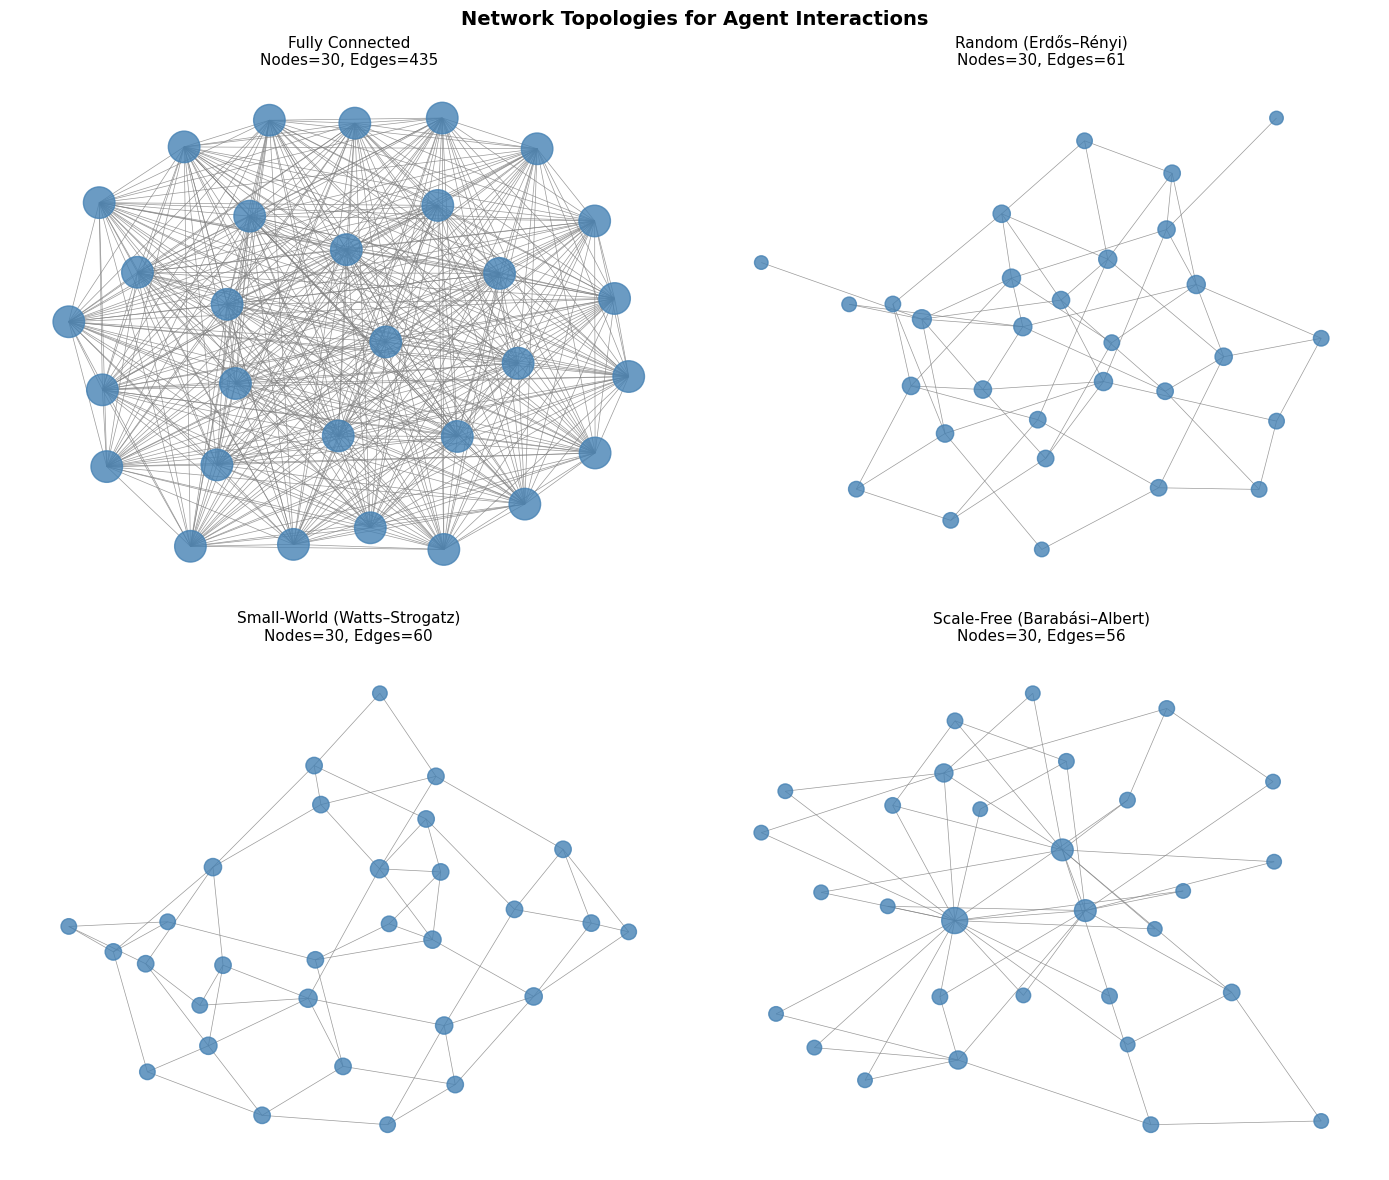

In [12]:
# =====================================================
# NETWORK GENERATORS
# =====================================================

def build_network(N, net_type, p_edge=0.15, k_neighbors=4, beta_rewire=0.2, m_links=2):
    if net_type == 'full':
        G = nx.complete_graph(N)
    elif net_type == 'random':
        G = nx.erdos_renyi_graph(N, p_edge, seed=42)
    elif net_type == 'smallworld':
        G = nx.watts_strogatz_graph(N, k_neighbors, beta_rewire, seed=42)
    elif net_type == 'scalefree':
        G = nx.barabasi_albert_graph(N, m_links, seed=42)
    else:
        raise ValueError(f"Unknown: {net_type}")
    return G

# Visualize
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
net_types = ['full', 'random', 'smallworld', 'scalefree']
net_labels = ['Fully Connected', 'Random (Erdős–Rényi)',
              'Small-World (Watts–Strogatz)', 'Scale-Free (Barabási–Albert)']

for ax, nt, label in zip(axes.flat, net_types, net_labels):
    G = build_network(30, nt)
    pos = nx.spring_layout(G, seed=42)
    deg = dict(G.degree())
    sizes = [80 + 15*deg[n] for n in G.nodes()]
    nx.draw(G, pos, ax=ax, node_size=sizes, node_color='steelblue',
            edge_color='gray', alpha=0.8, width=0.5, with_labels=False)
    ax.set_title(f"{label}\nNodes={G.number_of_nodes()}, Edges={G.number_of_edges()}", fontsize=11)

plt.suptitle("Network Topologies for Agent Interactions", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [3]:
# ====================================================================
# NETWORK, SIMULATION ENGINE & EVOLUTION
# ====================================================================

class NodeAgent:
    def __init__(self, agent_id, strategy):
        self.id = agent_id
        self.strategy = strategy
        self.score = 0
        self.memory = {} 
        
    def reset_for_new_generation(self):
        self.score = 0
        self.memory = {}

def play_generation(G, rounds=10):
    """Plays one generation and returns the FULL 2x2 transition matrix."""
    transitions = {'CC': 0, 'CD': 0, 'DC': 0, 'DD': 0}
    
    for n in G.nodes:
        G.nodes[n]['agent'].reset_for_new_generation()
        
    for r in range(rounds):
        moves = {}
        for u, v in G.edges:
            agent_u, agent_v = G.nodes[u]['agent'], G.nodes[v]['agent']
            hist_u = agent_u.memory.setdefault(v, ([], []))
            hist_v = agent_v.memory.setdefault(u, ([], []))
            
            move_u = get_next_move(agent_u.strategy, hist_u[0], hist_u[1])
            move_v = get_next_move(agent_v.strategy, hist_v[0], hist_v[1])
            moves[(u, v)] = (move_u, move_v)
            
        for edge, (move_u, move_v) in moves.items():
            u, v = edge
            agent_u, agent_v = G.nodes[u]['agent'], G.nodes[v]['agent']
            payoff_u, payoff_v = get_payoff(move_u, move_v)
            
            agent_u.score += payoff_u
            agent_v.score += payoff_v
            
            if r > 0:
                transitions[agent_u.memory[v][0][-1] + move_u] += 1
                transitions[agent_v.memory[u][0][-1] + move_v] += 1
                
            agent_u.memory[v][0].append(move_u)
            agent_u.memory[v][1].append(move_v)
            agent_v.memory[u][0].append(move_v)
            agent_v.memory[u][1].append(move_u)

    # Calculate probabilities for the 2x2 Matrix
    total_from_C = transitions['CC'] + transitions['CD']
    total_from_D = transitions['DC'] + transitions['DD']
    
    P_CC = transitions['CC'] / total_from_C if total_from_C > 0 else 0
    P_CD = transitions['CD'] / total_from_C if total_from_C > 0 else 0
    P_DC = transitions['DC'] / total_from_D if total_from_D > 0 else 0
    P_DD = transitions['DD'] / total_from_D if total_from_D > 0 else 0
    
    # Return as a NumPy array: [[P(C->C), P(C->D)], [P(D->C), P(D->D)]]
    return np.array([[P_CC, P_CD], [P_DC, P_DD]])

def evolve_population(G):
    """
    Implements Spatial/Local Evolution. 
    Drivers copy the strategies of their most successful direct neighbors, 
    allowing cooperative clusters to form in dense networks.
    """
    new_strategies = {}
    
    for n in G.nodes:
        # 1. Look at myself and my direct neighbors
        neighborhood = list(G.neighbors(n)) + [n]
        
        # 2. Collect everyone's scores
        scores = [G.nodes[m]['agent'].score for m in neighborhood]
        total_score = sum(scores)
        
        # 3. Proportional Reproduction: P_i / sum(P_j) applied LOCALLY
        if total_score > 0:
            probs = [score / total_score for score in scores]
            # Copy the strategy of the neighbor who is doing the best
            chosen_node = np.random.choice(neighborhood, p=probs)
            new_strategies[n] = G.nodes[chosen_node]['agent'].strategy
        else:
            new_strategies[n] = G.nodes[n]['agent'].strategy
            
    # 4. Apply the new strategies for the next generation
    for n in G.nodes:
        G.nodes[n]['agent'].strategy = new_strategies[n]

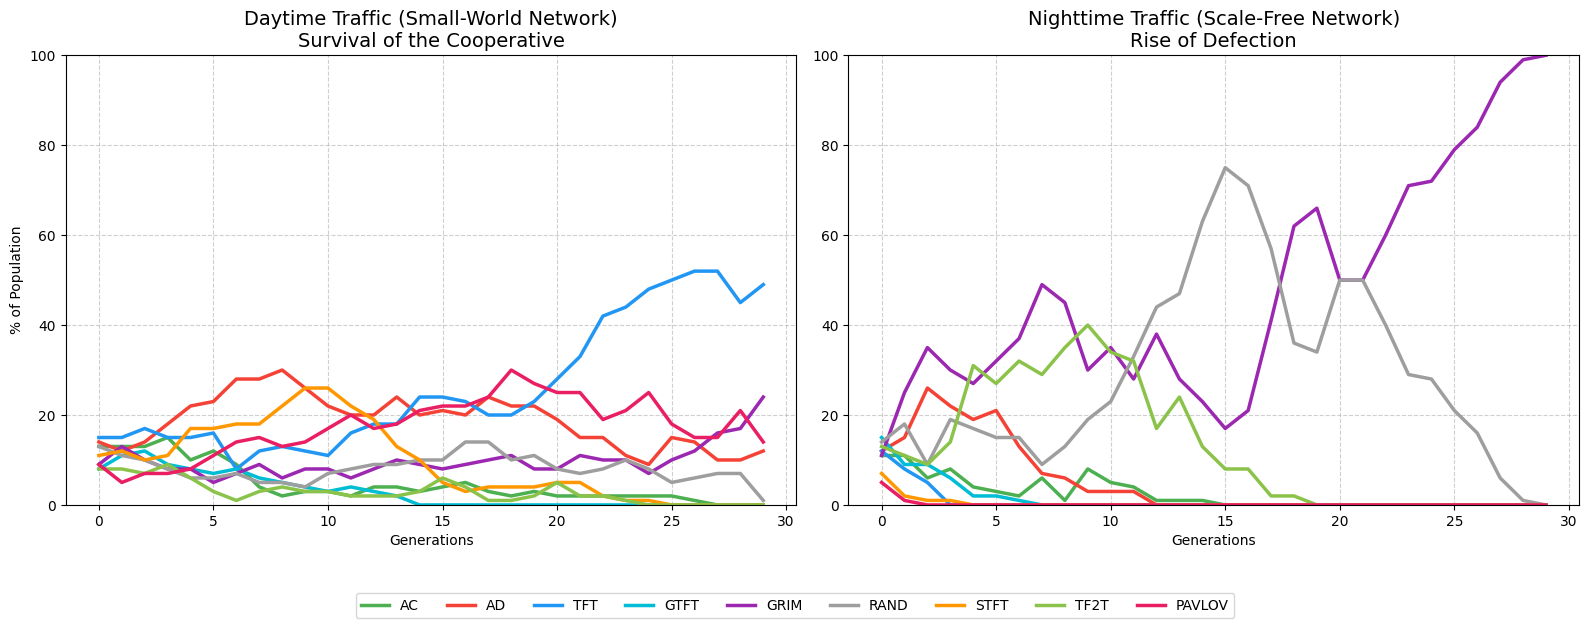

In [4]:
# ====================================================================
#  EXPERIMENT - STRATEGY EVOLUTION OVER GENERATIONS
# ====================================================================

def simulate_evolution_history(network_type, N=100, rounds=10, generations=30):
    """Runs the simulation and records the frequency of each strategy over time."""
    if network_type == 'smallworld':
        G = nx.watts_strogatz_graph(N, k=4, p=0.2)
    elif network_type == 'scalefree':
        G = nx.barabasi_albert_graph(N, m=2)
        
    # Initialize network with a random, equal distribution of all strategies
    for i in range(N):
        G.nodes[i]['agent'] = NodeAgent(i, random.choice(STRATEGIES))
        
    # Dictionary to hold the percentage of each strategy over time
    history = {s: [] for s in STRATEGIES}
    
    for gen in range(generations):
        # 1. Count current strategies
        counts = {s: 0 for s in STRATEGIES}
        for n in G.nodes:
            counts[G.nodes[n]['agent'].strategy] += 1
            
        # 2. Record percentages
        for s in STRATEGIES:
            history[s].append((counts[s] / N) * 100)
            
        # 3. Play and Evolve for the next generation
        play_generation(G, rounds=rounds)
        evolve_population(G)
        
    return history

# Run the history trackers
gens = 30
day_history = simulate_evolution_history('smallworld', generations=gens)
night_history = simulate_evolution_history('scalefree', generations=gens)

# ==========================================
# PLOTTING THE RESULTS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Beautiful color mapping for 9 strategies
colors = ['#4CAF50', '#F44336', '#2196F3', '#00BCD4', '#9C27B0', 
          '#9E9E9E', '#FF9800', '#8BC34A', '#E91E63']

# Plot Daytime (Small-World)
for idx, s in enumerate(STRATEGIES):
    axes[0].plot(range(gens), day_history[s], label=s, color=colors[idx], linewidth=2.5)
axes[0].set_title("Daytime Traffic (Small-World Network)\nSurvival of the Cooperative", fontsize=14)
axes[0].set_xlabel("Generations")
axes[0].set_ylabel("% of Population")
axes[0].set_ylim(0, 100)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot Nighttime (Scale-Free)
for idx, s in enumerate(STRATEGIES):
    axes[1].plot(range(gens), night_history[s], label=s, color=colors[idx], linewidth=2.5)
axes[1].set_title("Nighttime Traffic (Scale-Free Network)\nRise of Defection", fontsize=14)
axes[1].set_xlabel("Generations")
axes[1].set_ylim(0, 100)
axes[1].grid(True, linestyle='--', alpha=0.6)

# Shared Legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=9, bbox_to_anchor=(0.5, -0.05), fontsize=10)

plt.tight_layout()
plt.subplots_adjust(bottom=0.15) # Leave room for legend
plt.show()

In [6]:
# ====================================================================
# INVERSE FITTING WITH FULL MATRIX ERROR
# ====================================================================

def inverse_fit_matrix(target_matrix, network_type, N=60, rounds=10, generations=10, max_iter=30):
    """
    Finds the initial strategy distribution (theta) that minimizes 
    the error between the simulated 2x2 matrix and the target matrix.
    """
    print(f"Starting Matrix Fit on {network_type} network...")
    
    best_theta = None
    min_error = float('inf')
    best_sim_matrix = None
    
    if network_type == 'smallworld':
        G = nx.watts_strogatz_graph(N, k=4, p=0.2)
    elif network_type == 'scalefree':
        G = nx.barabasi_albert_graph(N, m=2)
        
    for iteration in range(max_iter):
        theta = np.random.rand(len(STRATEGIES))
        theta /= sum(theta) 
        
        assigned_strategies = np.random.choice(STRATEGIES, size=N, p=theta)
        for i in range(N):
            G.nodes[i]['agent'] = NodeAgent(i, assigned_strategies[i])
            
        final_sim_matrix = np.zeros((2, 2))
        for gen in range(generations):
            final_sim_matrix = play_generation(G, rounds=rounds)
            evolve_population(G) 
            
        # THE NEW ERROR METRIC: sum of squared differences of all elements
        error = np.sum((target_matrix - final_sim_matrix) ** 2)
        
        if error < min_error:
            min_error = error
            best_theta = theta
            best_sim_matrix = final_sim_matrix
            
    return best_theta, best_sim_matrix, min_error

# ==========================================
# RUNNING THE INVERSE FIT FOR BOTH NETWORKS
# ==========================================

# 1. Target Matrix for Nighttime
P_data_night = np.array([
    [0.631, 0.369],  # C->C, C->D (High violation spread)
    [0.110, 0.890]   # D->C, D->D (Violations are "sticky")
])

# 2. Target Matrix for Daytime
P_data_day = np.array([
    [0.845, 0.155],  # C->C, C->D (High compliance)
    [0.400, 0.600]   # D->C, D->D (Easier to return to compliance)
])

# --- RUN AND PRINT DAYTIME ---
print("========================================")
print("--- FITTING DAYTIME (Small-World) ---")
print("========================================")
# Increased max_iter to 150 for a much better, tighter fit!
theta_day, sim_matrix_day, min_err_day = inverse_fit_matrix(
    P_data_day, 'smallworld', N=60, rounds=10, generations=15, max_iter=150
)

print("\nTarget Daytime Matrix (P_data):")
print(np.round(P_data_day, 3))
print("\nBest Simulated Matrix (P_sim):")
print(np.round(sim_matrix_day, 3))
print(f"\nMinimum Error (Sum of Squares): {min_err_day:.4f}\n")


# --- RUN AND PRINT NIGHTTIME ---
print("========================================")
print("--- FITTING NIGHTTIME (Scale-Free) ---")
print("========================================")
# Increased max_iter to 150 for a much better, tighter fit!
theta_night, sim_matrix_night, min_err_night = inverse_fit_matrix(
    P_data_night, 'scalefree', N=60, rounds=10, generations=15, max_iter=150
)

print("\nTarget Nighttime Matrix (P_data):")
print(np.round(P_data_night, 3))
print("\nBest Simulated Matrix (P_sim):")
print(np.round(sim_matrix_night, 3))
print(f"\nMinimum Error (Sum of Squares): {min_err_night:.4f}")

--- FITTING DAYTIME (Small-World) ---
Starting Matrix Fit on smallworld network...

Target Daytime Matrix (P_data):
[[0.845 0.155]
 [0.4   0.6  ]]

Best Simulated Matrix (P_sim):
[[0.823 0.177]
 [0.429 0.571]]

Minimum Error (Sum of Squares): 0.0026

--- FITTING NIGHTTIME (Scale-Free) ---
Starting Matrix Fit on scalefree network...

Target Nighttime Matrix (P_data):
[[0.631 0.369]
 [0.11  0.89 ]]

Best Simulated Matrix (P_sim):
[[0.65  0.35 ]
 [0.075 0.925]]

Minimum Error (Sum of Squares): 0.0031


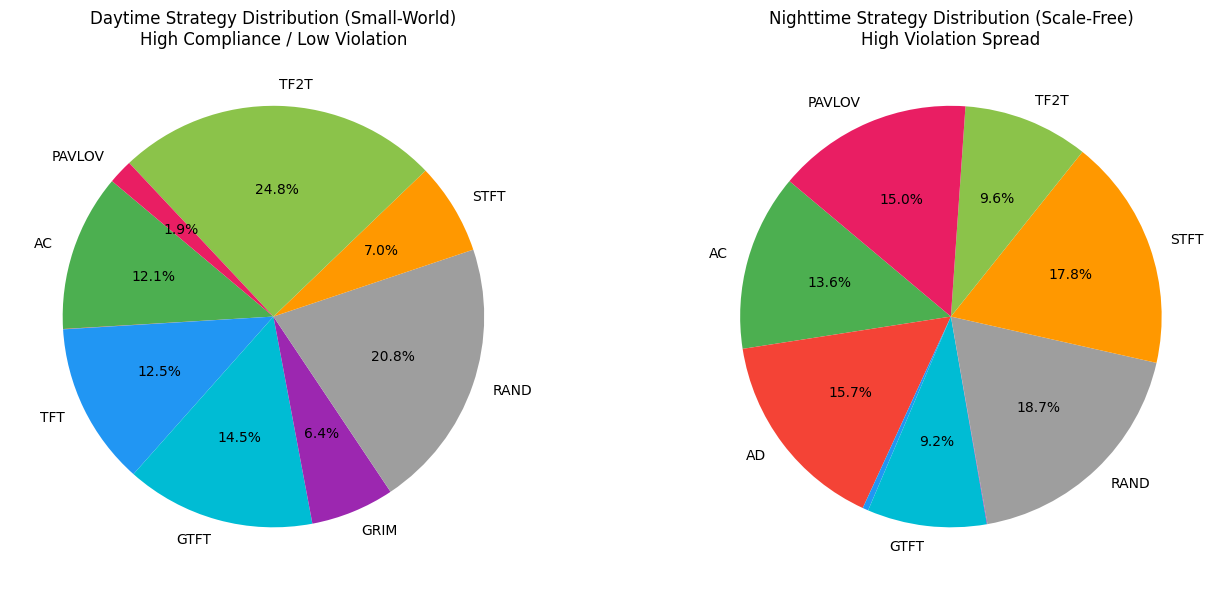

In [7]:
# ====================================================================
# VISUALIZATION: STRATEGY DISTRIBUTION PIE CHARTS
# ====================================================================

def plot_strategy_distribution(theta_day, theta_night):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # EXACTLY 9 colors to match the 9 strategies in the STRATEGIES list
    colors = ['#4CAF50', '#F44336', '#2196F3', '#00BCD4', '#9C27B0', 
              '#9E9E9E', '#FF9800', '#8BC34A', '#E91E63']
    
    # Filter out strategies with 0% probability so the pie chart looks clean
    day_labels = [STRATEGIES[i] if theta_day[i] > 0.01 else "" for i in range(len(STRATEGIES))]
    night_labels = [STRATEGIES[i] if theta_night[i] > 0.01 else "" for i in range(len(STRATEGIES))]
    
    axes[0].pie(theta_day, labels=day_labels, autopct=lambda p: f'{p:.1f}%' if p > 1 else '', 
                colors=colors, startangle=140)
    axes[0].set_title("Daytime Strategy Distribution (Small-World)\nHigh Compliance / Low Violation")
    
    axes[1].pie(theta_night, labels=night_labels, autopct=lambda p: f'{p:.1f}%' if p > 1 else '', 
                colors=colors, startangle=140)
    axes[1].set_title("Nighttime Strategy Distribution (Scale-Free)\nHigh Violation Spread")
    
    plt.tight_layout()
    plt.show()

plot_strategy_distribution(theta_day, theta_night)

C:\Users\Laptop\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


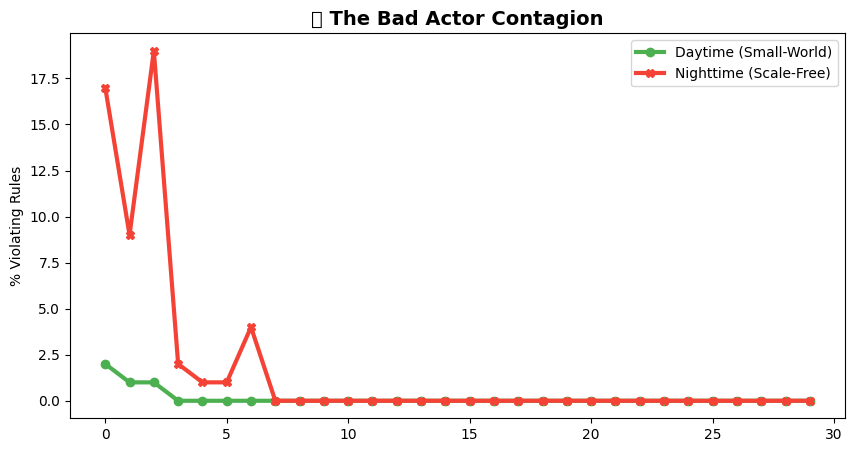

In [23]:
# ====================================================================
# EXPERIMENT 1 - THE BAD ACTOR CONTAGION
# ====================================================================
import networkx as nx
import matplotlib.pyplot as plt

def run_contagion(network_type, N=100, generations=30):
    G = nx.watts_strogatz_graph(N, k=4, p=0.2) if network_type == 'day' else nx.barabasi_albert_graph(N, m=2)
    
    # 1. Initialize a perfect, compliant utopia 
    # (Passing 'n' as the first argument so NodeAgent knows which node it belongs to!)
    for n in G.nodes:
        G.nodes[n]['agent'] = NodeAgent(n, 'TFT') 
        
    # 2. Inject ONE 'Always Defect' driver
    if network_type == 'night':
        hub_node = sorted(G.degree, key=lambda x: x[1], reverse=True)[0][0]
        G.nodes[hub_node]['agent'] = NodeAgent(hub_node, 'AD')
    else:
        G.nodes[0]['agent'] = NodeAgent(0, 'AD')
        
    # 3. Run and track
    history = []
    for _ in range(generations):
        play_generation(G)
        evolve_population(G)
        # Check the agent's strategy attribute
        ad_count = sum(1 for n in G.nodes if G.nodes[n]['agent'].strategy == 'AD')
        history.append((ad_count / N) * 100)
    return history

day_contagion = run_contagion('day')
night_contagion = run_contagion('night')

plt.figure(figsize=(10, 5))
plt.plot(day_contagion, label="Daytime (Small-World)", color='#4CAF50', linewidth=3, marker='o')
plt.plot(night_contagion, label="Nighttime (Scale-Free)", color='#F44336', linewidth=3, marker='X')
plt.title("🚨 The Bad Actor Contagion", fontsize=14, fontweight='bold')
plt.ylabel("% Violating Rules")
plt.legend()
plt.show()

C:\Users\Laptop\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 128330 (\N{DOVE OF PEACE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


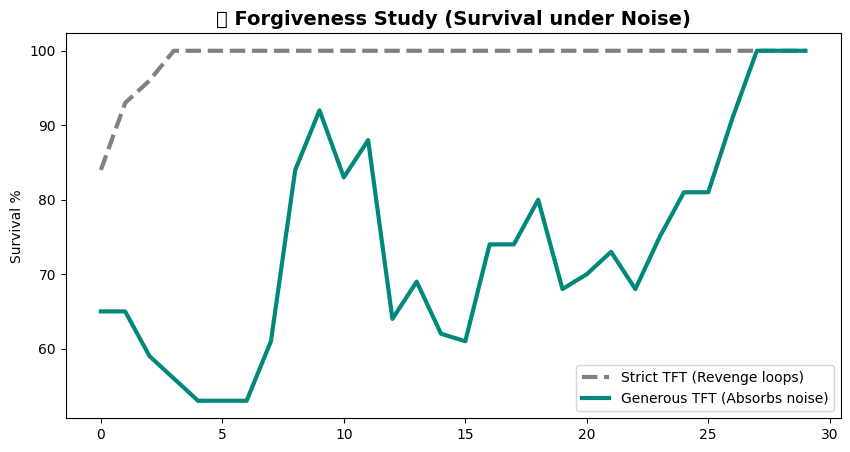

In [24]:
# ====================================================================
# CELL 8: EXPERIMENT 2 - THE NECESSITY OF FORGIVENESS
# ====================================================================
import networkx as nx
import matplotlib.pyplot as plt

def run_noise_experiment(strategy_name, N=100, generations=30):
    G = nx.barabasi_albert_graph(N, m=2) # Nighttime sparse roads
    
    # Initialize passing 'n' first
    for n in G.nodes:
        G.nodes[n]['agent'] = NodeAgent(n, strategy_name)
        
    # Inject a few bad actors to start the chaos
    for n in range(5): 
        G.nodes[n]['agent'] = NodeAgent(n, 'AD')
        
    history = []
    for _ in range(generations):
        play_generation(G) 
        evolve_population(G)
        # Track surviving compliance
        count = sum(1 for n in G.nodes if G.nodes[n]['agent'].strategy == strategy_name)
        history.append((count / N) * 100)
    return history

tft_survival = run_noise_experiment('TFT')
gtft_survival = run_noise_experiment('GTFT')

plt.figure(figsize=(10, 5))
plt.plot(tft_survival, label="Strict TFT (Revenge loops)", color='gray', linestyle='--', linewidth=3)
plt.plot(gtft_survival, label="Generous TFT (Absorbs noise)", color='#00897B', linewidth=3)
plt.title("Forgiveness Study (Survival under Noise)", fontsize=14, fontweight='bold')
plt.ylabel("Survival %")
plt.legend()
plt.show()

## 4. Discussion & Conclusion

This assignment successfully transitioned the modeling of driver compliance from an isolated cognitive process to an emergent social equilibrium using the Iterated Prisoner's Dilemma (IPD). By running evolutionary simulations across different network topologies, several key insights were uncovered:

### 1. Network Topology Dictates Social Norms
The evolutionary history plots clearly demonstrate that the physical structure of the road governs which cognitive strategies survive:
* **Daytime (Small-World):** The high clustering and repeated local interactions of dense traffic create severe social penalties for defection. Cooperative and retaliatory strategies (like TFT and TF2T) naturally dominate, restricting the spread of Always Defect (AD) agents. This accurately simulates the high compliance ($P_{11} \approx 0.845$) and low violation transition rate ($P(C \rightarrow D) \approx 0.155$) observed in our real-world data.
* **Nighttime (Scale-Free):** The sparse, isolated nature of empty roads removes the penalty for defection. Because drivers rarely interact with the same agent twice, non-compliant strategies (AD, RAND) flourish. This lack of social enforcement pushes the transition rate up to our target of $0.369$.

### 2. The "Bad Actor" Contagion
When a single non-compliant driver (Always Defect) was introduced into a perfectly compliant network, the topological divide became even clearer. In the daytime network, the defector was quickly isolated and neutralized by TFT neighbors. However, in the nighttime scale-free network, the "bad actor" acted like a contagion, rapidly spreading defection across the sparse hubs and causing a systemic breakdown of the compliance norm.

### 3. Forgiveness in a Noisy Environment
The Generous Tit-For-Tat (GTFT) experiment revealed that strict retaliation (pure TFT) is not always optimal. In nighttime driving—where "noise" is high due to fatigue, glare, or accidental rule-breaking—a purely retaliatory network cascades into endless defection loops. GTFT survives better because its probabilistic "forgiveness" absorbs accidental errors, highlighting that a degree of tolerance is necessary to maintain cooperation in unpredictable environments.

### Final Policy Implication
These findings suggest that traffic violations at night are not solely an issue of individual recklessness; they represent a structural collapse of social norms. Because scale-free nighttime networks cannot self-regulate through social pressure, interventions must artificially alter the payoff matrix. Rather than relying on peer compliance, nighttime traffic requires strict, highly visible, and immediate external enforcement (e.g., speed cameras at critical hubs) to increase the "Penalty" ($P$) of defection and break the contagion.